<a href="https://colab.research.google.com/github/ai-agent-yonsei/agent/blob/main/5_1_Multi_Agent_Framework_I.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-Agent Frameworks I  

**목표:** 동일한 문의를 Single Agent, Supervisor, Routed Parallel로 처리하고 **정확도, LLM Call수, 입/출력 토큰, 지연 시간** 비교

  
| 단계 | 확인 개념
|---|---|  
| 실습 1 | Single Agent 기준선
| 실습 2 | Role Card, Supervisor-Worker
| 실습 3 | Router, LangGraph Send, 병렬 fan-out
| 실습 4 | 점수, 호출, 입력/출력 토큰, 지연 비교  
| 실습 5 | 권한 경계, 도구 허용 목록, 감사 로그
| 실습 6 | Writer → Critic → Reviser, 종료 조건  
| 실습 7 | 불필요한 Reviewer 제거 실험


In [4]:
# 패키지 설치 : LangGraph = Agent 간 실행 흐름을 그래프로 표현하는 프레임워크
# langchain-openai = OpenAI 모델을 LangGraph 노드에서 호출하기 위한 연결 패키지
!pip -q install -U langgraph langchain-openai pandas matplotlib


In [5]:
import os

# 1순위: Colab Secrets에 등록한 OPENAI_API_KEY 확인
try:
    from google.colab import userdata
    os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
except Exception:
    pass  # Colab이 아니거나 Secrets에 키가 없으면 다음 단계로

# 2순위: 키가 아직 없으면 입력 창을 띄움
if not os.environ.get("OPENAI_API_KEY"):
    from getpass import getpass
    os.environ["OPENAI_API_KEY"] = getpass("OpenAI API 키를 입력: ")

print("API 키 준비 완료:", os.environ["OPENAI_API_KEY"][:7] + "…")

API 키 준비 완료: sk-proj…


LLM 호출 함수 & 사용량 기록기

`LOG`에 **입력 토큰, 출력 토큰, 전체 토큰, LLM 응답 시간, 담당 Agent, 문의 ID** 저장

- **LLM calls:** 모델 API를 호출한 횟수
- **Input tokens:** 모델 입력량
- **Output tokens:** 모델 출력량
- **Elapsed:** 실제 모델 요청의 경과 시간
- **Cost:** 가격표  



In [6]:
import json, time
import pandas as pd
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage

# 모델 & 안전 상한 설정
MODEL_NAME = "gpt-4.1-mini"
CALL_LIMIT = 120             # 예상치 못한 반복 호출 방지를 위한 전체 API 호출 상한
RUN_ALL_QUERIES = False      # False = Q7만 비교, True = Q1/Q2/Q3/Q7 모두 비교


# 단위: USD / 100만 토큰 (gpt-4.1-mini기준)
INPUT_USD_PER_1M = 0.4
OUTPUT_USD_PER_1M = 1.6 # 필요 시 None 입력 가능

llm = ChatOpenAI(model=MODEL_NAME, temperature=0, max_retries=2, timeout=60)
LOG = []
NOW = {"design": "-", "qid": "-"}

def call_llm(agent, model, messages):
    # 모든 LLM 호출을 이 함수로 통과
    if len(LOG) >= CALL_LIMIT:
        raise RuntimeError(f"LLM 호출 상한 {CALL_LIMIT}회 초과, 셀 반복 실행 여부 확인 필요")
    started = time.perf_counter()
    response = model.invoke(messages)
    elapsed = time.perf_counter() - started

    # LangChain 응답의 usage_metadata에서 실제 토큰 사용량 읽기
    usage = response.usage_metadata or {}
    in_tok = int(usage.get("input_tokens") or 0)
    out_tok = int(usage.get("output_tokens") or 0)
    total_tok = int(usage.get("total_tokens") or (in_tok + out_tok))
    cost = None
    if INPUT_USD_PER_1M is not None and OUTPUT_USD_PER_1M is not None:
        cost = (in_tok * INPUT_USD_PER_1M + out_tok * OUTPUT_USD_PER_1M) / 1_000_000

    LOG.append({**NOW, "agent": agent, "model": MODEL_NAME,
                "input_tokens": in_tok, "output_tokens": out_tok,
                "tokens": total_tok, "seconds": round(elapsed, 3), "usd_est": cost})
    return response

def call_json(agent, system, user):
    # Supervisor의 다음 Worker 선택을 JSON으로 수신하기 위한 함수
    json_model = llm.bind(response_format={"type": "json_object"})
    response = call_llm(agent, json_model, [SystemMessage(content=system), HumanMessage(content=user)])
    try:
        return json.loads(response.content)
    except (json.JSONDecodeError, TypeError):
        print(f"[WARN] {agent}: JSON 해석 실패, 안전하게 종료")
        return {"next": "FINISH"}

print("모델:", MODEL_NAME, "| 전체 문의 실행:", RUN_ALL_QUERIES)
print("실제 API 호출은 다음 실습 실행 시 시작")


모델: gpt-4.1-mini | 전체 문의 실행: False
실제 API 호출은 다음 실습 실행 시 시작


## Y-Bank 가상 데이터, Tool, 질문 세트


In [7]:
from langchain_core.tools import tool

# 가상 은행 데이터, 외부 서비스 연결 없음
BANK = {
    "C001": {"balance": "3,250,000원", "card_limit": "3,000,000원",
             "transactions": ["10/02 해외결제 USD 89.00", "10/02 해외결제 수수료 12,400원",
                              "10/02 해외결제 수수료 12,400원 (중복 출금)"]},
    "C002": {"balance": "870,000원", "card_limit": "1,500,000원",
             "transactions": ["10/05 급여 입금 2,800,000원"]},
}
PRODUCTS = "정기예금(12개월) 연 3.2%, 자유적금(12개월) 연 3.6%"
POLICIES = {
    "수수료 환불": "중복 출금이 확인되면 3영업일 이내 환불한다. 문의: 고객센터 1588-0000",
    "사기 의심":   "즉시 지급정지를 신청하고 112에 신고하도록 안내한다.",
    "한도 증액":   "카드 한도 증액은 심사 담당자의 승인이 필요하다.",
}

# LLM이 호출할 수 있는 Tool 정의, 실제로는 5개
@tool
def get_balance(customer_id: str) -> str:
    "고객번호(예: C001)로 입출금 계좌 잔액을 조회한다."
    return f"{customer_id} 잔액: {BANK[customer_id]['balance']}" if customer_id in BANK else "고객번호 없음"

@tool
def get_transactions(customer_id: str) -> str:
    "고객번호로 최근 거래내역을 조회한다."
    return " / ".join(BANK[customer_id]["transactions"]) if customer_id in BANK else "고객번호 없음"

@tool
def get_card_limit(customer_id: str) -> str:
    "고객번호로 현재 카드 한도를 조회한다."
    return f"{customer_id} 카드 한도: {BANK[customer_id]['card_limit']}" if customer_id in BANK else "고객번호 없음"

@tool
def get_products() -> str:
    "판매 중인 예금, 적금 상품과 금리를 조회한다."
    return PRODUCTS

@tool
def lookup_policy(topic: str) -> str:
    "은행 규정을 찾는다. topic은 '수수료 환불', '사기 의심', '한도 증액' 중 하나."
    return POLICIES.get(topic, "해당 규정 없음. 가능한 주제: " + ", ".join(POLICIES))

ALL_TOOLS = [get_balance, get_transactions, get_card_limit, get_products, lookup_policy]
print("도구:", [t.name for t in ALL_TOOLS])
print(get_balance.invoke({"customer_id": "C001"}))

도구: ['get_balance', 'get_transactions', 'get_card_limit', 'get_products', 'lookup_policy']
C001 잔액: 3,250,000원


###   Q1, Q2, Q3, Q7과 간단 채점

** 동일한 시험 문제와 동일한 정답 사실을 사용해 구조 간 비교 **


In [8]:
QUERIES = [
    {"id": "Q1", "text": "C001 고객입니다. 제 입출금 계좌 잔액이 얼마인가요?",
     "expect": ["3,250,000"], "owner": "account"},
    {"id": "Q2", "text": "정기예금과 자유적금 금리를 비교해 주세요.",
     "expect": ["3.2%", "3.6%"], "owner": "product"},
    {"id": "Q3", "text": "C001입니다. 해외결제 수수료가 두 번 빠져나갔어요. 환불되나요?",
     "expect": ["12,400", "3영업일"], "owner": "care"},
    {"id": "Q7", "text": "C001입니다. 계좌 잔액 확인하고, 남는 돈으로 가입할 정기예금 금리도 알려주세요.",
     "expect": ["3,250,000", "3.2%"], "owner": "account + product"},
]

def score(answer, expect):
    # 공백을 지운 뒤 정답 사실이 몇 개 들어 있는지 센다. (0.0 ~ 1.0)
    norm = answer.replace(" ", "")
    return sum(e.replace(" ", "") in norm for e in expect) / len(expect)

pd.DataFrame(QUERIES)[["id", "text", "owner", "expect"]]

,id,text,owner,expect
0,Q1,C001 고객입니다. 제 입출금 계좌 잔액이 얼마인가요?,account,"[3,250,000]"
1,Q2,정기예금과 자유적금 금리를 비교해 주세요.,product,"[3.2%, 3.6%]"
2,Q3,C001입니다. 해외결제 수수료가 두 번 빠져나갔어요. 환불되나요?,care,"[12,400, 3영업일]"
3,Q7,"C001입니다. 계좌 잔액 확인하고, 남는 돈으로 가입할 정기예금 금리도 알려주세요.",account + product,"[3,250,000, 3.2%]"


###  Agent 공통 실행기와 도구 권한 검사

  Agent별 구현을 달리하면 구조 비교가 어려워짐. 동일한 Tool Calling 반복 루틴을 공유하고 역할 프롬프트와 허용 Tool만 변경

실행 흐름: LLM → Tool 호출 요청 → Python 허용 목록 검사 → Tool 실행 → LLM 최종 답변


In [9]:
AUDIT = []   # 감사 로그: (에이전트, 도구, 허용 여부)

def execute_tool(agent, tool_name, args, allowed):
    # LLM이 무엇을 요청하든, 실행 직전에 허용 목록을 코드로 확인함
    ok = tool_name in allowed
    AUDIT.append((agent, tool_name, ok))
    if not ok:
        return f"ERROR: {agent}에게 허용되지 않은 도구({tool_name})라 실행하지 않았습니다."
    try:
        return allowed[tool_name].invoke(args)
    except Exception as e:
        return f"ERROR: 도구 실행 실패 ({e})"

ANSWER_RULE = ("도구 결과에 있는 사실만 써서 한국어로 간결히 답하라. 숫자는 도구 결과의 표기 그대로 쓴다. "
               "필요한 정보(예: 고객번호)가 없으면 추측하지 말고 고객에게 요청하라.")

def run_agent(name, role_prompt, tools, question, max_steps=4):
    # 에이전트 하나 = 역할 프롬프트 + 허용 도구 + 공통 루틴
    allowed = {t.name: t for t in tools}
    model = llm.bind_tools(tools) if tools else llm      # LLM에게는 허용 도구만 보여 줌
    messages = [SystemMessage(role_prompt + "\n" + ANSWER_RULE), HumanMessage(question)]
    for _ in range(max_steps):                           # 무한 반복을 막는 단계 상한
        ai = call_llm(name, model, messages)
        messages.append(ai)
        if not ai.tool_calls:                            # 도구가 더 필요 없으면 이것이 최종 답
            return ai.content
        for tc in ai.tool_calls:                         # 요청한 도구를 (권한 확인 후) 실행
            result = execute_tool(name, tc["name"], tc["args"], allowed)
            messages.append(ToolMessage(content=str(result), tool_call_id=tc["id"]))
    return "(단계 상한 도달) 답변을 완성하지 못했습니다."

def run_design(design_name, answer_fn):
    # 같은 문의 세트를 한 설계로 모두 돌리고, 문의별 점수, 호출, 토큰을 표로 만듬
    rows = []
    test_queries = QUERIES if RUN_ALL_QUERIES else [q for q in QUERIES if q["id"] == "Q7"]
    for q in test_queries:
        NOW.update(design=design_name, qid=q["id"])
        before = len(LOG)
        started = time.perf_counter()
        answer = answer_fn(q["text"])
        wall_seconds = time.perf_counter() - started
        calls = LOG[before:]
        rows.append({"design": design_name, "qid": q["id"], "score": score(answer, q["expect"]),
                     "calls": len(calls),
                     "input_tokens": sum(c["input_tokens"] for c in calls),
                     "output_tokens": sum(c["output_tokens"] for c in calls),
                     "tokens": sum(c["tokens"] for c in calls),
                     "wall_seconds": round(wall_seconds, 3),
                     "llm_seconds_sum": round(sum(c["seconds"] for c in calls), 3),
                     "usd_est": (sum(c["usd_est"] for c in calls) if all(c["usd_est"] is not None for c in calls) else None),
                     "answer": answer})
    return pd.DataFrame(rows)

## 실습 1. Single Agent 기준선

Multi-Agent 도입 전 단일 Agent의 정답 사실 포함률, 호출 수, 토큰 사용량, 지연 시간 측정. Single로 충분하면 Multi-Agent 불필요할 수 있음

**구조 :** 고객 질문 → 모든 Tool을 가진 Single Agent → 최종 답변


In [10]:
# 모든 Tool을 가진 통합 상담 Agent
SINGLE_PROMPT = "너는 Y-Bank 통합 상담원이다. 필요한 도구만 골라 고객 질문에 답하라."

def single_agent(question):
    # 같은 run_agent 사용, 역할만 통합 상담원으로 지정
    return run_agent("single", SINGLE_PROMPT, ALL_TOOLS, question)

# 비교 기준선 저장, 이후 다른 구조와 함께 비교
single_df = run_design("single", single_agent)
display(single_df[["qid", "score", "calls", "input_tokens", "output_tokens", "tokens", "wall_seconds", "answer"]])


,qid,score,calls,input_tokens,output_tokens,tokens,wall_seconds,answer
0,Q7,1.0,2,668,96,764,2.865,"C001님의 계좌 잔액은 3,250,000원입니다. 정기예금 12개월 금리는 연 3..."


 단일 문의에서도 Tool 선택과 답변 생성 때문에 LLM이 여러 번 호출될 수 있음


## 실습 2. Role Card & Supervisor-Worker

** 역할은 Persona가 아니라 책임, Tool 권한, Context, 완료 기준의 경계**
Supervisor는 처리할 Worker를 결정하고 결과를 Synthesizer에 전달함

**구조 :** Supervisor → Worker → Supervisor(필요 시 반복) → Synthesizer


In [11]:
# 역할 카드: 목적, 허용 도구, 하지 않는 일
ROLE_CARDS = {
    "account": {"prompt": "너는 Y-Bank 계좌 담당이다. 잔액, 거래내역, 카드 한도만 다룬다. 상품 추천이나 민원 판단은 하지 않는다.",
                "tools": [get_balance, get_transactions, get_card_limit]},
    "product": {"prompt": "너는 Y-Bank 상품 담당이다. 예금, 적금 상품과 금리만 안내한다. 고객 계좌 정보는 다루지 않는다.",
                "tools": [get_products]},
    "care":    {"prompt": "너는 Y-Bank 고객보호 담당이다. 민원, 환불, 사기 문의에 규정에 맞게 1차 답변한다. 환불을 직접 실행하지는 않는다.",
                "tools": [get_transactions, lookup_policy]},
}
WORKERS = list(ROLE_CARDS)

def run_worker(name, question):
    card = ROLE_CARDS[name]
    return run_agent(name, card["prompt"], card["tools"], question)

pd.DataFrame([{"역할": k, "허용 도구": [t.name for t in v["tools"]], "역할 설명": v["prompt"]} for k, v in ROLE_CARDS.items()])

,역할,허용 도구,역할 설명
0,account,"[get_balance, get_transactions, get_card_limit]","너는 Y-Bank 계좌 담당이다. 잔액, 거래내역, 카드 한도만 다룬다. 상품 추천..."
1,product,[get_products],"너는 Y-Bank 상품 담당이다. 예금, 적금 상품과 금리만 안내한다. 고객 계좌 ..."
2,care,"[get_transactions, lookup_policy]","너는 Y-Bank 고객보호 담당이다. 민원, 환불, 사기 문의에 규정에 맞게 1차 ..."


### 2-2. LangGraph Supervisor 구성

다중 의도 Q7에서 Supervisor가 다음 Worker를 선택하는 흐름 확인. Worker 실행 후 다시 Supervisor로 복귀하는 중앙형 구조 구현

- **State:** 질문, Agent 결과, 다음 Worker, 단계 수 보관
- **Node:** Agent가 실행되는 단위
- **Edge:** 다음 실행 노드의 연결
- **Synthesizer:** 여러 Worker 결과를 고객용 답변 하나로 통합
- **MAX_STEPS:** 무한 반복 방지


In [12]:
import operator
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END

class TeamState(TypedDict):
    question: str
    answers: Annotated[list, operator.add]  # 워커 답변을 '덧붙여' 모은다 (reducer)
    next: str                               # 감독자가 고른 다음 워커
    steps: int                              # 감독자가 결정한 횟수
    final: str                              # 최종 고객 응답

def make_worker_node(name):
    # 워커 노드: 문의를 처리하고 자기 답변 하나를 answers에 추가함
    def node(state):
        return {"answers": [{"worker": name, "answer": run_worker(name, state["question"])}]}
    return node

def synthesize(state):
    # 합성 노드: 워커 답변들을 하나의 고객 응답으로 합친다.
    parts = "\n".join(f"- {a['worker']}: {a['answer']}" for a in state["answers"]) or "(답변 없음)"
    ai = call_llm("synthesizer", llm, [
        SystemMessage("워커 답변들을 하나의 고객 응답으로 합쳐라. 숫자는 표기 그대로, 빠뜨리지 마라."),
        HumanMessage(f"문의: {state['question']}\n워커 답변:\n{parts}")])
    return {"final": ai.content}

MAX_STEPS = 4
def supervisor(state):
    done = [a["worker"] for a in state["answers"]]
    decision = call_json("supervisor",
        f"너는 Y-Bank 상담 감독자다. 워커: account(잔액, 거래, 한도), product(예금, 적금 금리), care(민원, 환불, 사기). "
        f"문의에서 아직 처리되지 않은 일이 있으면 담당 워커 이름을, 모두 처리됐으면 FINISH를 "
        '{"next": "..."} JSON으로 답하라. 이미 완료된 워커는 다시 고르지 마라.',
        f"문의: {state['question']}\n완료된 워커: {done}")
    nxt = decision.get("next", "FINISH")
    # 안전장치 ①: 없는 워커, 이미 끝난 워커 → 종료 / 안전장치 ②: 단계 상한
    if nxt not in WORKERS or nxt in done or state["steps"] >= MAX_STEPS:
        nxt = "FINISH"
    return {"next": nxt, "steps": state["steps"] + 1}

g = StateGraph(TeamState)
g.add_node("supervisor", supervisor)
for w in WORKERS:
    g.add_node(w, make_worker_node(w))
    g.add_edge(w, "supervisor")                      # 워커는 항상 감독자에게 돌아감
g.add_node("synthesize", synthesize)
g.add_edge(START, "supervisor")
g.add_conditional_edges("supervisor",                # 감독자의 결정에 따라 다음 노드를 고름
                        lambda s: "synthesize" if s["next"] == "FINISH" else s["next"],
                        WORKERS + ["synthesize"])
g.add_edge("synthesize", END)
supervisor_graph = g.compile()

def supervisor_team(question):
    out = supervisor_graph.invoke({"question": question, "answers": [], "next": "", "steps": 0, "final": ""})
    return out["final"]

# 그래프의 연결(엣지)을 확인함. 결과에서 (조건부) 표시는 감독자의 결정에 따라 갈라지는 경로를 의미
for e in supervisor_graph.get_graph().edges:
    print(f"{e.source:>11} → {e.target:<11}", "(조건부)" if e.conditional else "")

  __start__ → supervisor  
    account → supervisor  
       care → supervisor  
    product → supervisor  
 supervisor → account     (조건부)
 supervisor → care        (조건부)
 supervisor → product     (조건부)
 supervisor → synthesize  (조건부)
 synthesize → __end__     


### 2-3. Supervisor 실행 및 호출 Trace

같은 질문을 Supervisor 구조로 실행한 뒤 Single과 비교. 특히 Q7에서 Supervisor 호출과 Worker 호출이 얼마나 늘어나는지 확인


In [13]:
# Supervisor 방식 실행, LOG에 Agent별 호출과 토큰 기록
sup_df = run_design("supervisor", supervisor_team)

# Q7의 LLM 호출 순서를 순서대로 표시
q7_path = [c["agent"] for c in LOG if c["design"] == "supervisor" and c["qid"] == "Q7"]
print("Q7 호출 순서:", " → ".join(q7_path))
display(sup_df[["qid", "score", "calls", "input_tokens", "output_tokens", "tokens", "wall_seconds", "answer"]])


Q7 호출 순서: supervisor → account → account → supervisor → product → product → supervisor → synthesizer


,qid,score,calls,input_tokens,output_tokens,tokens,wall_seconds,answer
0,Q7,1.0,8,1493,221,1714,6.372,"C001님의 계좌 잔액은 3,250,000원입니다. 정기예금 12개월 금리는 연 3..."


Supervisor가 매 단계 LLM을 호출하므로 통제와 감사 가능성의 대가로 호출, 토큰, 지연 증가 가능. Supervisor와 Synthesizer는 다른 역할임


## 실습 3. Routed Parallel

** Q7처럼 독립적인 잔액 조회와 금리 조회를 병렬 실행. Supervisor를 반복 호출하지 않고 **규칙 Router가 필요한 Worker만 선택**하도록 구성

- **Routing:** 불필요한 Agent 호출 제거
- **Parallel:** 여러 Agent가 동시에 실행되어 대기 시간 단축 가능
- **LangGraph Send:** 선택된 Worker 수만큼 병렬 작업 생성

**한계:** 키워드 Router는 표현이 바뀌면 누락 가능. Router는 LLM Agent가 아닌 Python 규칙임


In [14]:
from langgraph.types import Send

ROUTE_KEYWORDS = {
    "account": ["잔액", "계좌", "거래", "한도"],
    "product": ["금리", "예금", "적금", "상품"],
    "care":    ["환불", "수수료", "민원", "사기"],
}

def keyword_router(question):
    # 키워드가 하나라도 맞는 워커를 모두 고른다 (다중 의도 지원). 아무것도 없으면 사람이 볼 수 있는 care로
    hits = [w for w, kws in ROUTE_KEYWORDS.items() if any(k in question for k in kws)]
    return hits or ["care"]

def router_node(state):
    return {}   # 라우팅 결정은 아래 fan_out 함수가 함 (LLM 호출 없음)

def fan_out(state):
    # 고른 워커마다 병렬 작업 하나씩 보냄
    return [Send(w, {"question": state["question"], "answers": []}) for w in keyword_router(state["question"])]

def build_routed(with_reviewer=False):
    g = StateGraph(TeamState)
    g.add_node("router", router_node)
    for w in WORKERS:
        g.add_node(w, make_worker_node(w))
    g.add_node("synthesize", synthesize)
    g.add_edge(START, "router")
    g.add_conditional_edges("router", fan_out, WORKERS)
    after = "synthesize"
    if with_reviewer:
        g.add_node("reviewer", lazy_reviewer)
        g.add_edge("reviewer", "synthesize")
        after = "reviewer"
    for w in WORKERS:
        g.add_edge(w, after)                # 병렬 워커가 모두 끝나면 다음 단계로 모임
    g.add_edge("synthesize", END)
    return g.compile()

routed_graph = build_routed()

def routed_team(question, graph=None):
    out = (graph or routed_graph).invoke({"question": question, "answers": [], "next": "", "steps": 0, "final": ""})
    return out["final"]

for q in QUERIES:
    print(q["id"], "→", keyword_router(q["text"]))

Q1 → ['account']
Q2 → ['product']
Q3 → ['care']
Q7 → ['account', 'product']


In [15]:
# Routed Parallel 실행, 동일한 질문과 채점 기준 사용
routed_df = run_design("routed", routed_team)
display(routed_df[["qid", "score", "calls", "input_tokens", "output_tokens", "tokens", "wall_seconds", "answer"]])


,qid,score,calls,input_tokens,output_tokens,tokens,wall_seconds,answer
0,Q7,1.0,5,1230,343,1573,3.137,"C001님의 계좌 잔액은 3,250,000원이고, 카드 한도는 3,000,000원입..."


### 선택 실습. Broadcast vs Routed  

Broadcast는 모든 Worker 실행, Routed는 필요한 Worker만 실행. Q7에서 **불필요한 Care 호출이 추가되는지** 직접 확인


In [16]:
from concurrent.futures import ThreadPoolExecutor

RUN_BROADCAST_DEMO = True  # True로 변경 시 Q7에 대해 추가 LLM 호출 발생

def broadcast_team(question):
    # 모든 Worker에게 동일한 문의 전달, 필요 여부와 무관하게 3개 실행
    with ThreadPoolExecutor(max_workers=3) as pool:
        futures = {w: pool.submit(run_worker, w, question) for w in WORKERS}
        answers = [{"worker": w, "answer": future.result()} for w, future in futures.items()]

    # Worker 결과를 기존 Synthesizer로 통합, 비교 조건 통일
    return synthesize({"question": question, "answers": answers})["final"]

if RUN_BROADCAST_DEMO:
    broadcast_df = run_design("broadcast", broadcast_team)
    print("[Q7 Broadcast 결과]")
    display(broadcast_df[["qid", "calls", "input_tokens", "output_tokens", "tokens", "wall_seconds", "score"]])
    print("[Q7 Routed 결과]")
    display(routed_df[["qid", "calls", "input_tokens", "output_tokens", "tokens", "wall_seconds", "score"]])
else:
    print("선택 실습 비활성화, RUN_BROADCAST_DEMO=True로 변경 시 실행")


[Q7 Broadcast 결과]


,qid,calls,input_tokens,output_tokens,tokens,wall_seconds,score
0,Q7,6,1442,425,1867,4.264,0.5


[Q7 Routed 결과]


,qid,calls,input_tokens,output_tokens,tokens,wall_seconds,score
0,Q7,5,1230,343,1573,3.137,1.0


병렬 실행은 호출 수를 자동으로 줄이지는 않음. Router가 호출 대상 수를 줄이고 Parallel이 전체 경과 시간을 줄이는  효과


## 실습 4. 세 구조 비교

구조 선택을 감이 아닌 숫자로 판단. 같은 문의에 대한 정답 사실 포함률, API 호출 수, 입력 토큰, 출력 토큰, 총 토큰, 전체 경과 시간 비교

**주의:** `llm_seconds_sum`은 병렬 Worker 호출 시간의 합, `wall_seconds`는 사용자가 실제로 기다린 시간. 두 값이 다를 수 있음


[설계별 평균 비교]


,score,calls_per_q,input_per_q,output_per_q,tokens_per_q,wall_seconds,llm_seconds_sum,score_per_1k_tokens
design,,,,,,,,
single,1.0,2.0,668.0,96.0,764.0,2.865,2.859,1.309
supervisor,1.0,8.0,1493.0,221.0,1714.0,6.372,6.363,0.583
routed,1.0,5.0,1230.0,343.0,1573.0,3.137,4.356,0.636


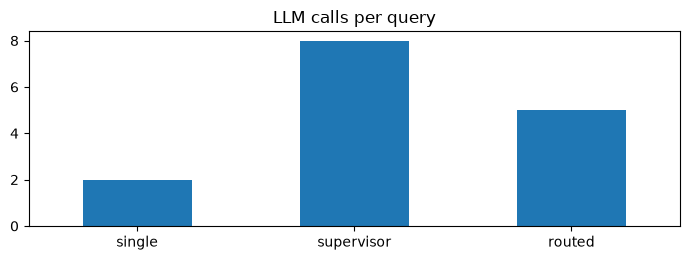

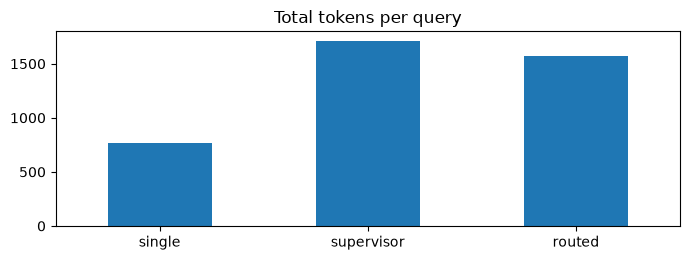

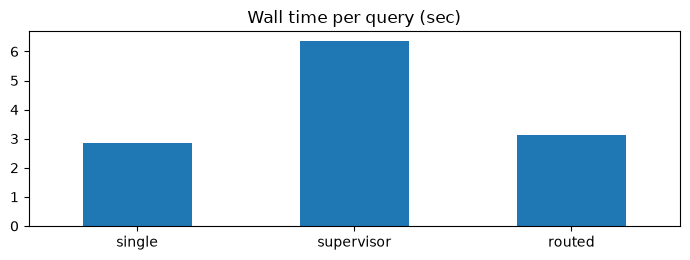

[추정 API 비용 USD, 실제 청구 금액과 차이 가능]


,sum,mean
design,,
routed,0.001041,0.001041
single,0.000421,0.000421
supervisor,0.000951,0.000951


In [17]:
import matplotlib.pyplot as plt

# 동일한 문의에 대해 세 설계 결과 합치기
results = pd.concat([single_df, sup_df, routed_df], ignore_index=True)

# 설계별 평균 지표 계산, 입력 토큰과 출력 토큰을 분리해서 확인
summary = (results.groupby("design", sort=False)
           .agg(score=("score", "mean"),
                calls_per_q=("calls", "mean"),
                input_per_q=("input_tokens", "mean"),
                output_per_q=("output_tokens", "mean"),
                tokens_per_q=("tokens", "mean"),
                wall_seconds=("wall_seconds", "mean"),
                llm_seconds_sum=("llm_seconds_sum", "mean")))

# 단위 토큰당 점수는 보조 지표, 정답 사실 포함률이 동일할 때 효율 비교용
summary["score_per_1k_tokens"] = summary["score"] / summary["tokens_per_q"].replace(0, float("nan")) * 1000
print("[설계별 평균 비교]")
display(summary.round(3))

# 비교 대상의 단위가 다르므로 차트를 분리
for col, title in [("calls_per_q", "LLM calls per query"),
                   ("tokens_per_q", "Total tokens per query"),
                   ("wall_seconds", "Wall time per query (sec)")]:
    ax = summary[col].plot(kind="bar", figsize=(7, 2.7), rot=0, title=title)
    ax.set_xlabel("")
    plt.tight_layout()
    plt.show()

# USD 추정 비용 표시
if INPUT_USD_PER_1M is not None and OUTPUT_USD_PER_1M is not None:
    print("[추정 API 비용 USD, 실제 청구 금액과 차이 가능]")
    display(results.groupby("design")["usd_est"].agg(["sum", "mean"]))


품질이 비슷하면 호출, 토큰, 지연이 작은 구조가 효율적일 가능성. 권한 분리와 감사 추적 같은 비기능 요구는 단순 점수에 나타나지 않음


## 실습 5. Tool 권한 검사

역할 프롬프트만으로는 권한 통제가 보장되지 않음. Tool 실행 직전 Python 허용 목록 검사와 감사 로그 기록


In [18]:
# Product Agent의 허용 Tool 목록 구성
product_allowed = {t.name: t for t in ROLE_CARDS["product"]["tools"]}

# 권한 밖 도구 호출을 의도적으로 시도, 실제 실행은 차단되어야 정상
print(execute_tool("product", "get_card_limit", {"customer_id": "C001"}, product_allowed))

# 허용된 상품 Tool은 정상 실행
print(execute_tool("product", "get_products", {}, product_allowed))

# 누가 어떤 Tool을 요청했는지 감사 로그 확인
audit_df = pd.DataFrame(AUDIT, columns=["agent", "tool", "allowed"])
print("[차단된 Tool 요청]")
display(audit_df[~audit_df["allowed"]])


ERROR: product에게 허용되지 않은 도구(get_card_limit)라 실행하지 않았습니다.
정기예금(12개월) 연 3.2%, 자유적금(12개월) 연 3.6%
[차단된 Tool 요청]


,agent,tool,allowed
11,product,get_card_limit,False


권한 밖 Tool 요청은 `allowed=False`로 기록. 역할 분리는 프롬프트뿐 아니라 코드 수준의 실행 경계가 필요


## 실습 5-2. Delegation Contract 예시

Agent에게 단순 질문이 아닌 **목표, 입력, 금지 행동, 결과 형식, 완료 조건**을 전달하는 위임 지시서 학습. 아래 셀은 확인용으로 추가 LLM 호출 없음


In [19]:
# Supervisor가 Account Agent에게 전달할 위임 지시서 예시
contract = {
    "goal": "C001 잔액 조회",
    "context": {"customer_id": "C001"},
    "constraints": ["조회만 허용", "이체 금지", "상품 추천 금지"],
    "output": {"balance": "string"},
    "done": "정확한 잔액 반환",
    "budget": {"max_llm_calls": 2}
}

# 지시서의 각 필드 확인, 실제 Agent 호출이나 권한 부여는 수행하지 않음
print(json.dumps(contract, ensure_ascii=False, indent=2))


{
  "goal": "C001 잔액 조회",
  "context": {
    "customer_id": "C001"
  },
  "constraints": [
    "조회만 허용",
    "이체 금지",
    "상품 추천 금지"
  ],
  "output": {
    "balance": "string"
  },
  "done": "정확한 잔액 반환",
  "budget": {
    "max_llm_calls": 2
  }
}


## 실습 6. Writer → Critic → Reviser

민원 답변(Q3)에 대한 독립 검토와 수정 실습. Critic이 누락된 항목을 확인하고 Reviser가 보완하는 협업 패턴

- **루브릭:** 사과, 사실 확인, 조치와 기한, 근거 규정, 추가 채널
- **종료 조건:** 5/5 달성 또는 최대 3라운드
- **비용:** 라운드 증가에 따른 LLM 호출 및 토큰 증가 확인


In [20]:
RUBRIC = {   # 항목: 답변에 들어 있어야 할 표현(하나라도 있으면 통과)
    "사과":        ["죄송", "사과"],
    "사실 확인":   ["12,400"],
    "조치와 기한": ["3영업일"],
    "근거 규정":   ["규정"],
    "추가 채널":   ["고객센터", "1588"],
}
def rubric_check(text):
    missing = [item for item, kws in RUBRIC.items() if not any(k in text for k in kws)]
    return len(RUBRIC) - len(missing), missing

NOW.update(design="critic-reviser", qid="Q3")
FACTS = get_transactions.invoke({"customer_id": "C001"}) + " / 규정: " + lookup_policy.invoke({"topic": "수수료 환불"})

# 1) writer: 일부러 짧은 초안(2문장)부터 시작. 개선 과정을 보기 위함
draft = call_llm("writer", llm, [
    SystemMessage("너는 Y-Bank 고객보호 담당이다. 고객 민원에 2문장 이내로 짧게 답하라."),
    HumanMessage(f"문의: {QUERIES[2]['text']}\n확인된 사실: {FACTS}")]).content

history = []
for round_no in range(1, 4):                       # 종료 조건 ①: 최대 3라운드
    points, missing = rubric_check(draft)
    history.append({"round": round_no, "rubric": f"{points}/5", "missing": missing, "draft": draft})
    if not missing:                                # 종료 조건 ②: 5/5 달성(승인)
        break
    # 2) critic: 빠진 항목을 보완할 방법을 조언함
    advice = call_llm("critic", llm, [
        SystemMessage("너는 민원 답변 검토자다. 빠진 항목을 어떻게 보완할지 한두 문장으로 조언하라."),
        HumanMessage(f"초안: {draft}\n빠진 항목: {missing}\n확인된 사실: {FACTS}")]).content
    # 3) reviser: 조언을 반영해 다시 씀
    draft = call_llm("reviser", llm, [
        SystemMessage("너는 Y-Bank 고객보호 담당이다. 조언을 반영해 답변을 고쳐 써라. 사실은 확인된 사실만 쓴다."),
        HumanMessage(f"초안: {draft}\n조언: {advice}\n확인된 사실: {FACTS}")]).content

pd.set_option("display.max_colwidth", 200)
display(pd.DataFrame(history))
print("총 LLM 호출:", sum(1 for c in LOG if c["design"] == "critic-reviser"))

,round,rubric,missing,draft
0,1,3/5,"[사과, 근거 규정]","중복 출금된 해외결제 수수료 12,400원은 확인 후 3영업일 이내 환불해드리겠습니다. 추가 문의는 고객센터 1588-0000으로 연락 바랍니다."
1,2,5/5,[],"중복 출금으로 불편을 드려 죄송합니다. 10월 2일 발생한 해외결제 수수료 12,400원이 중복 출금된 사실을 확인하였으며, 당사 규정에 따라 중복 출금이 확인된 경우 3영업일 이내에 환불해드리고 있습니다. 환불 절차 진행에 대해 추가 문의가 있으시면 고객센터(1588-0000)로 연락해 주시기 바랍니다."


총 LLM 호출: 3


점수가 오르더라도 호출과 토큰이 증가. 초안이 처음부터 충분하면 Critic 단계가 추가 가치를 제공하지 않을 수 있음


## 실습 7. 불필요한 Reviewer 제거 실험 - 협업 실패 패턴

Reviewer가 존재한다는 사실만으로 품질 향상 보장 불가. 같은 Routed 구조에서 Reviewer 유무에 따른 점수와 비용 차이 확인

**Ablation:** 특정 구성 요소를 제거하고 전후 차이를 비교하는 실험


In [21]:
def lazy_reviewer(state):
    # 일부러 만든 '게으른' 검토자: 무엇을 받든 같은 말만 출력함
    ai = call_llm("reviewer", llm, [
        SystemMessage("너는 검토자다. 무엇을 받든 '검토 결과 특이사항 없습니다.'라고만 답하라."),
        HumanMessage("\n".join(a["answer"] for a in state["answers"]))])
    return {"answers": [{"worker": "reviewer", "answer": ai.content}]}

reviewed_graph = build_routed(with_reviewer=True)
reviewed_df = run_design("routed+reviewer", lambda q: routed_team(q, reviewed_graph))

ablation = pd.DataFrame({
    "평균 점수":   [routed_df["score"].mean(), reviewed_df["score"].mean()],
    "문의당 토큰": [routed_df["tokens"].mean(), reviewed_df["tokens"].mean()],
    "문의당 호출": [routed_df["calls"].mean(), reviewed_df["calls"].mean()],
}, index=["검토자 없음", "검토자 있음"])
display(ablation.round(2))
print("검토자의 기여(점수 차이):", round(ablation["평균 점수"].iloc[1] - ablation["평균 점수"].iloc[0], 2))

,평균 점수,문의당 토큰,문의당 호출
검토자 없음,1.0,1573.0,5.0
검토자 있음,1.0,1432.0,6.0


검토자의 기여(점수 차이): 0.0


품질 차이가 없고 토큰만 증가하면 Reviewer의 기여가 제한적일 가능성. 다만 규제와 감사 목적 등 다른 성과 지표도 고려 필요


## 9. 최종 정리  

| 설계 질문 | 실습에서 확인한 것 |
|---|---|
| Single로 충분한가? | 실습 1의 점수와 비용이 기준선 |
| 역할을 나눌 근거가 있는가? | 실습 2의 Role Card와 Tool 권한 |
| 누가 작업을 선택하는가? | 실습 2 Supervisor 또는 실습 3 Router |
| 독립 하위 과제인가? | 실습 3 Q7 병렬 실행 |
| 통제 비용이 얼마인가? | 실습 4 호출 수, 토큰, 지연 |
| 권한이 강제되는가? | 실습 5 실행 전 검사와 감사 로그 |
| 독립 검증이 도움이 되는가? | 실습 6 Critic, 실습 7 Ablation |

**핵심:** Multi-Agent는 기본값이 아니라, 정확도와 비용 그리고 역할 경계에 근거해 선택하는 설계


In [22]:
# 모든 실습에서 발생한 실제 LLM 호출 기록 확인
usage = pd.DataFrame(LOG)
if usage.empty:
    print("LLM 호출 기록 없음, 위 실습 실행 필요")
else:
    print(f"전체 LLM 호출: {len(usage)}회")
    print(f"입력 토큰: {usage['input_tokens'].sum():,}")
    print(f"출력 토큰: {usage['output_tokens'].sum():,}")
    print(f"전체 토큰: {usage['tokens'].sum():,}")

    # 설계별 요약, Agent별 요약, 상세 Trace를 각각 표시
    display(usage.groupby("design", sort=False).agg(
        calls=("agent", "count"), input_tokens=("input_tokens", "sum"),
        output_tokens=("output_tokens", "sum"), total_tokens=("tokens", "sum"),
        llm_seconds_sum=("seconds", "sum")).round(3))
    display(usage.groupby(["design", "agent"], sort=False).agg(
        calls=("agent", "count"), tokens=("tokens", "sum")).reset_index())
    print("\n[최근 LLM 호출 Trace]")
    display(usage.tail(15))


전체 LLM 호출: 30회
입력 토큰: 6,664
출력 토큰: 1,552
전체 토큰: 8,216


,calls,input_tokens,output_tokens,total_tokens,llm_seconds_sum
design,,,,,
single,2,668,96,764,2.859
supervisor,8,1493,221,1714,6.363
routed,5,1230,343,1573,4.356
broadcast,6,1442,425,1867,6.298
critic-reviser,3,627,239,866,2.862
routed+reviewer,6,1204,228,1432,5.050


,design,agent,calls,tokens
0,single,single,2,764
1,supervisor,supervisor,3,440
2,supervisor,account,2,649
3,supervisor,product,2,416
4,supervisor,synthesizer,1,209
5,routed,product,2,416
6,routed,account,2,858
7,routed,synthesizer,1,299
8,broadcast,product,2,405
9,broadcast,care,2,728



[최근 LLM 호출 Trace]


,design,qid,agent,model,input_tokens,output_tokens,tokens,seconds,usd_est
15,broadcast,Q7,product,gpt-4.1-mini,160,10,170,0.495,0.000080
16,broadcast,Q7,care,gpt-4.1-mini,218,49,267,0.765,0.000166
17,broadcast,Q7,account,gpt-4.1-mini,230,59,289,0.817,0.000186
18,broadcast,Q7,product,gpt-4.1-mini,205,30,235,0.732,0.000130
19,broadcast,Q7,care,gpt-4.1-mini,345,116,461,1.125,0.000324
20,broadcast,Q7,synthesizer,gpt-4.1-mini,284,161,445,2.364,0.000371
21,critic-reviser,Q3,writer,gpt-4.1-mini,155,48,203,0.663,0.000139
22,critic-reviser,Q3,critic,gpt-4.1-mini,196,87,283,0.967,0.000218
23,critic-reviser,Q3,reviser,gpt-4.1-mini,276,104,380,1.232,0.000277
24,routed+reviewer,Q7,product,gpt-4.1-mini,160,28,188,0.930,0.000109
